# Reto Text-based Personality Computing: predicindo Big-5 a partir de Reddit
**Equipo:** `VAIA` · **Integrantes:** _Lucas Amado Oseira, María Lestón Geada, Iria Varela Palmás_

Obxectivo: predicir para cada usuario/a de test as 5 dimensións Big Five (0–100) a partir das súas publicacións. Métrica: **RMSE medio das 5 dimensións**.

Estrutura do notebook:
1. Configuración e carga de datos
2. Exploración
3. Preparación a nivel de usuario/a
4. Baseline (media do train)
5. Modelo 1: TF-IDF + Ridge
6. Modelo 2: embeddings SBERT + Ridge
7. Comparación e xeración dos CSV de envío

In [ ]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
import zipfile, os

TEAM = "VAIA"          # <- cambiar
DATA = "./material"           # carpeta cos CSV
TRAITS = ["agreeableness","openness","conscientiousness","extraversion","neuroticism"]
SEED = 2710

## 1. Carga de datos
O enunciado non detalla as columnas de `posts.csv`/`authors_*.csv`; axusta `USER_COL` e `TEXT_COL` despois de ver as cabeceiras.

In [ ]:
# Descomprimimos o zip e lemos os CSVs
z = zipfile.ZipFile(f"material.zip", "r")
z.extractall(f"{DATA}/")

posts = pd.read_csv(f"{DATA}/posts_v2.csv")
tr = pd.read_csv(f"{DATA}/authors_train.csv")
te = pd.read_csv(f"{DATA}/authors_test.csv")
print(posts.shape, tr.shape, te.shape)
print(posts.columns.tolist()); print(tr.columns.tolist()); print(te.columns.tolist())
posts.head()

KeyboardInterrupt: 

In [ ]:
# Listamos body de posts de BigSexy
posts_u = posts[posts['username'] == '-BigSexy-']
for element in posts_u['body'].tolist():
    print(element)

I've been asked to cum everywhere with my ex just to experiment. She preferred that I cum in the condom or if I pulled out than on her chest. She didn't mind her face but she didn't prefer it.
So south they're north?
Took mine.
let me know. I'd be down.
Guessing by you're username, anyone to the right of Chomsky is a fascist to you. It's become a hollow cheap insult at this point. It doesn't mean anything anymore. You and your leftist cronys have diluted the meaning and power behind a once feared word...just like you do to nations and economies. You suck the life out of everything you guys touch.
- The Federalist Papers- An Inquiry into the Wealth of Nations- Common Sense- Democracy in America- The Road to Serfdom- A theory of Justice
[And look at the damage you wrought trying to fix it with state intervention](https://www.youtube.com/watch?v=lm-FqtAOSB8)
Good selling point.This is part of my problem. I lean towards this is wrong because it's what I've been taught however I am always o

In [ ]:
# Contamos número de nulos por columna
print(posts.isnull().sum())
print(tr.isnull().sum())
print(te.isnull().sum())

# Borramos filas con body nulo
posts = posts.dropna(subset=['body'])

# Imputamos media de cada trait en tr
for trait in TRAITS:
    tr[trait] = tr[trait].fillna(tr[trait].mean())

username    0
body        0
dtype: int64
username              0
agreeableness         4
openness             18
conscientiousness     4
extraversion          3
neuroticism           7
dtype: int64
username               0
agreeableness        323
openness             323
conscientiousness    323
extraversion         323
neuroticism          323
dtype: int64


In [ ]:
USER_COL = "username"   # <- comprobar
TEXT_COL = next((c for c in ["body","text","content","selftext","post","title"] if c in posts.columns), None)
print("Columna de texto:", TEXT_COL)
assert USER_COL in posts.columns and TEXT_COL, "Axusta USER_COL / TEXT_COL"

Columna de texto: body


## 2. Exploración

       agreeableness  openness  conscientiousness  extraversion  neuroticism
count         1288.0    1288.0             1288.0        1288.0       1288.0
mean            42.8      62.6               39.5          37.3         49.7
std             31.2      27.6               30.0          30.6         32.2
min              0.0       0.0                0.0           0.0          0.0
25%             14.8      44.0               13.0          10.0         19.0
50%             40.0      69.0               35.0          30.0         49.7
75%             70.0      86.0               63.0          61.6         82.0
max            100.0      99.0               99.0          99.0         99.0


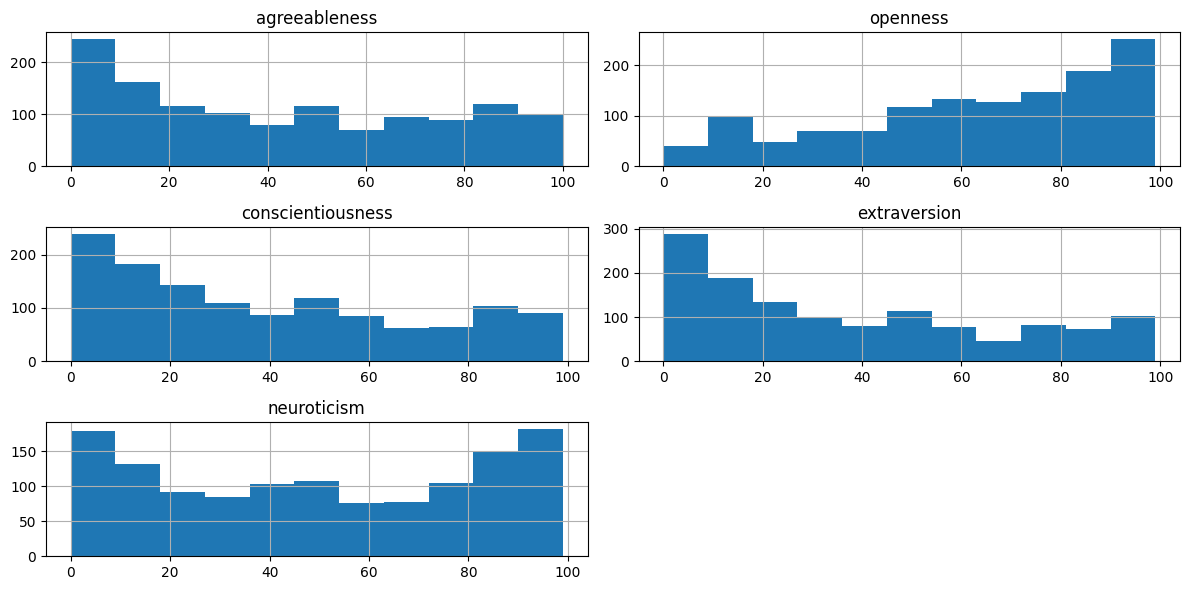

Correlacións entre trazos:
                   agreeableness  openness  conscientiousness  extraversion  \
agreeableness               1.00      0.12               0.05          0.04   
openness                    0.12      1.00              -0.05          0.22   
conscientiousness           0.05     -0.05               1.00          0.04   
extraversion                0.04      0.22               0.04          1.00   
neuroticism                 0.05     -0.00              -0.26         -0.25   

                   neuroticism  
agreeableness             0.05  
openness                 -0.00  
conscientiousness        -0.26  
extraversion             -0.25  
neuroticism               1.00  
Publicacións por usuario/a:
count     1572.0
mean      1988.1
std       4554.7
min          1.0
25%         85.0
50%        432.0
75%       1865.5
max      66350.0
dtype: float64


In [ ]:
print(tr[TRAITS].describe().round(1))
tr[TRAITS].hist(bins=11, figsize=(12,6)); plt.tight_layout(); plt.show()
print("Correlacións entre trazos:"); print(tr[TRAITS].corr().round(2))
n = posts.groupby(USER_COL).size()
# ESTO QUITEINO PORQUE TARDA A DIOS E A SU MADRE
# ||||||||||||||||||||||||||||||||||||||||||||||
# VVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVV
# print("Publicacións por usuario/a:"); print(n.describe().round(1))
# print("Lonxitude media (palabras):", posts[TEXT_COL].astype(str).str.split().str.len().mean().round(1))

## 3. Agregación a nivel de usuario/a
Concatenamos as publicacións de cada usuario/a (máximo `MAX_CHARS` para limitar o custo).

In [ ]:
MAX_CHARS = 20000
def clean(t):
    t = re.sub(r"http\S+", " URL ", str(t))
    return re.sub(r"\s+", " ", t).strip()

user_text = (posts.assign(_t=posts[TEXT_COL].map(clean))
                  .groupby(USER_COL)["_t"].apply(lambda s: " ".join(s)[:MAX_CHARS]))
train = tr.merge(user_text.rename("text"), left_on=USER_COL, right_index=True, how="left")
test  = te.merge(user_text.rename("text"), left_on=USER_COL, right_index=True, how="left")
print(train["text"].isna().sum(), "train sen texto;", test["text"].isna().sum(), "test sen texto")
train["text"] = train["text"].fillna(""); test["text"] = test["text"].fillna("")
Y = train[TRAITS].values

29 train sen texto; 10 test sen texto


## 4. Utilidades de validación (K-fold, RMSE medio)

In [ ]:
def rmse_mean(y, p): return np.sqrt(((y-p)**2).mean(axis=0)).mean()
def rmse_by_trait(y, p): return dict(zip(TRAITS, np.sqrt(((y-p)**2).mean(axis=0)).round(2)))

def cv_eval(fit_predict, X, Y, k=5):
    oof = np.zeros_like(Y, dtype=float)
    for tri, vai in KFold(k, shuffle=True, random_state=SEED).split(X):
        oof[vai] = fit_predict(X[tri], Y[tri], X[vai])
    return rmse_mean(Y, oof), rmse_by_trait(Y, oof), oof

texts = train["text"].values

## 5. Baseline: predicir a media do train

In [ ]:
base = lambda Xtr,Ytr,Xva: np.tile(Ytr.mean(axis=0), (len(Xva),1))
s_base, d_base, _ = cv_eval(base, texts, Y)
print("Baseline RMSE:", round(s_base,3), d_base)

Baseline RMSE: nan {'agreeableness': np.float64(nan), 'openness': np.float64(nan), 'conscientiousness': np.float64(nan), 'extraversion': np.float64(nan), 'neuroticism': np.float64(nan)}


## 6. Modelo 1: TF-IDF + Ridge
Vectorización clásica con n-gramas e regresión lineal regularizada (multi-saída).

In [ ]:
def tfidf_ridge(alpha=3.0):
    def f(Xtr,Ytr,Xva):
        m = make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2, max_df=0.9, ngram_range=(1,2), max_features=200000),
                          Ridge(alpha=alpha))
        m.fit(Xtr, Ytr); return np.clip(m.predict(Xva), 0, 100)
    return f
for a in [1, 3, 10, 30]:
    s, d, _ = cv_eval(tfidf_ridge(a), texts, Y)
    print(f"alpha={a:>3}  RMSE={s:.3f}  {d}")

ValueError: Input y contains NaN.

## 7. Modelo 2: embeddings SBERT + Ridge
Codificamos fragmentos de texto con Sentence-BERT e facemos a media por usuario/a. Require `pip install sentence-transformers` (mellor con GPU/Colab).

In [ ]:
# from sentence_transformers import SentenceTransformer
# sbert = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
# def embed_user(u_posts, max_posts=200):
#     return sbert.encode(u_posts[:max_posts], batch_size=64, normalize_embeddings=True).mean(axis=0)
# users = pd.concat([train[USER_COL], test[USER_COL]]).unique()
# g = posts.groupby(USER_COL)[TEXT_COL].apply(lambda s: [clean(x) for x in s])
# E = {u: embed_user(g[u]) for u in users if u in g.index}
# np.save("emb_sbert.npy", E, allow_pickle=True)

In [ ]:
# Ridge sobre embeddings (descomentar cando E estea calculado)
# Etr = np.vstack([E.get(u, np.zeros(384)) for u in train[USER_COL]])
# for a in [1, 10, 100]:
#     f = lambda Xtr,Ytr,Xva: np.clip(Ridge(alpha=a).fit(Xtr,Ytr).predict(Xva),0,100)
#     s,d,_ = cv_eval(f, Etr, Y); print(a, round(s,3), d)

## 8. Xeración dos CSV de envío
Formato: `team_name, variant_name, username, agreeableness, openness, conscientiousness, extraversion, neuroticism`; ficheiro `nome_equipo_nome_variante.csv`.

In [ ]:
def make_submission(variant, preds):
    df = pd.DataFrame(np.clip(preds,0,100), columns=TRAITS)
    df.insert(0, "username", test[USER_COL].values)
    df.insert(0, "variant_name", variant); df.insert(0, "team_name", TEAM)
    assert len(df)==len(te) and df[TRAITS].notna().all().all()
    fn = f"{TEAM}_{variant}.csv"; df.to_csv(fn, index=False); print("Gardado", fn)
    return df

make_submission("baseline", base(texts, Y, test["text"].values))
make_submission("tfidf_ridge", tfidf_ridge(10)(texts, Y, test["text"].values))

## 9. Resultados e discusión
_(Encher: táboa comparativa de RMSE por modelo e trazo, análise de erros, que funcionou e que non, ideas futuras: filtrado de publicacións por trazo, cuestionarios con SBERT, fine-tuning, LLMs few-shot.)_